# Исследование согласованности методов классификации MI и детекции OOD
## Cross-session эксперимент (feet и rest как OOD)


Для анализа использовались 4 датасета (в сумме 39 участников)
* BNCI2014_001: 9 участников (https://bnci-horizon-2020.eu/database/data-sets)
* Zhou2016: 4 участника (https://doi.org/10.6084/m9.figshare.2061654)
* Zhou2020: 20 участников (https://doi.org/10.21227/f1c7-7x89)
* TTK 2022: 6 участников из 9, для которых есть сессии в разные дни (https://repo.researchdata.hu/dataset.xhtml?persistentId=hdl:21.15109/CONCORDA/UOQQVK)

Были выбраны датасеты, в которых несколько сессий, есть классы right_hand, left_hand, feet, rest (или можно извлечь аналог rest).
Для датасета TTK категория feet формируется из left_foot, right_foot.
В датасете Zhou2020 берутся размеченные пробы rest, в TTK аннотация "Stimulus/S 1". В датасете Zhou2016 пробы с rest вырезались в интервале 5.5–8.5 с после MI-события, в BNCI2014_001 нарезались 3-секундные окна с шагом 3с из калибровочной записи с открытыми глазами.

Для анализа использовался интервал 3 сек., данные были приведены к частоте 250 Гц, использовались данные с 7 электродов, которые есть во всех датасетах ("FC3", "FCz", "FC4", "C3", "C4", "CP3", "CP4"). Применена фильтрация 8–32 Гц.

Обучение проводилось только на классах right_hand/left_hand. Для детекции OOD использовались классы feet и rest.

### Cross-session: Обучение проводилось на первой сессии, тест проводился на второй сессии.

Проверялись следующие методы

| Классификация MI | Детекция OOD |
|---|---|
| ACM+TS+SVM | ACM+TS+OCSVM |
| FBCSP+ElasticNet | FBCSP+IsolationForest |
| Log-bandpower+shLDA | Log-bandpower+Mahalanobis |
| Microstates+GB | Microstates+LOF |
| VAR+shLDA | VAR+Mahalanobis |
| ShallowConvNet | ShallowConvNet+kNN |
| EEGNet | EEGNet+TempDens (адаптация метода [Liu et al. (2026)](https://arxiv.org/abs/2605.01014)) |

Для каждого участника и каждого метода записывались

* Balanced accuracy и ROC AUC для классификации: MI_BA, MI_AUROC
* ROC AUC для детекции OOD (для feet и rest отдельно)

Данные по всем участникам: [cross-session_7-channels-feet-rest.csv](./results/cross-session_7-channels-feet-rest.csv)

## Проверяемые гипотезы

* H1: разные MI-классификаторы согласованно ранжируют участников по качеству классификации.
* H2: разные OOD-детекторы согласованно ранжируют участников по качеству детекции отдельно для feet и rest.
* H3: участники с более высоким качеством MI-классификации имеют более высокое качество OOD-детекции.

Дополнительно сравниваются согласованность и различия OOD-оценок feet и rest у одних и тех же участников.


Код: 
- [pipelines.py](./pipelines.py) -- Пайплайны
- [methods.py](./methods.py) -- Методы, используемые в пайплайнах
- [processing.py](./processing.py) -- Загрузка и обработка данных, обучение и расчет метрик
- [analysis.py](./analysis.py) -- Вспомогательные функции для анализа
- [experiment_cross-session_7ch_feet_rest.ipynb](./experiment_cross-session_7ch_feet_rest.ipynb) -- Запуск эксперимента

## Выводы: 
* Есть связь между ранжированием участников у методов классификации MI и методов детекции OOD. 
* Эта связь больше выражена для детекции feet как OOD, чем состояния покоя (rest).
* Ранжирование участников для методов детекции OOD с классами feet и rest частично совпадает, но хорошее качество детекции в одной категории не всегда совпадает с качеством детекции во второй.

In [1]:
from pathlib import Path
from analysis import *
from processing import create_exp_file, display_summary_by_dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from scipy.stats import bootstrap, permutation_test, spearmanr, wilcoxon
from IPython.display import display

DATASETS = ["BNCI2014_001", "Zhou2016", "Zhou2020", "TTK"]
EXPERIMENT = "cross-session_7-channels-feet-rest"
RESULTS = Path("results")
OOD_TYPES = {
    "feet": "ood-feet",
    "rest": "ood-rest",
}
MI_METHODS = [ "ACM+TS+SVM", "FBCSP+ElasticNet", "ShallowConvNet", "EEGNet", "Microstates+GB", "VAR+shLDA", "Log-bandpower+shLDA" ]
OOD_METHODS = [ "ACM+TS+OCSVM", "FBCSP+IsolationForest", "ShallowConvNet+kNN", "EEGNet+TempDens", "Log-bandpower+Mahalanobis", "Microstates+LOF", "VAR+Mahalanobis" ]
MI_METRICS = ("MI_BA", "MI_AUROC")
OOD_METRICS = ("OOD_AUROC_feet", "OOD_AUROC_rest")

filename = create_exp_file(EXPERIMENT, res_path=RESULTS)

/Users/liza/Projects/bci-motor-imagery/.venv/lib/python3.11/site-packages/optuna/integration/sklearn.py:14: FutureWarning: `optuna.integration.sklearn` has been deprecated in v4.9.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v4.9.0. Use `optuna_integration.sklearn` instead.
  optuna_warn(f"{msg} Use `optuna_integration.sklearn` instead.", FutureWarning)


Saved to results/cross-session_7-channels-feet-rest.csv


## Средние результаты по методам

Показываются MI BA, MI AUROC и OOD AUROC по методу, датасету и OOD-категории. Для MI-метрик категория отражает исходный запуск и его временное окно.


In [2]:
data = pd.read_csv(filename)

data = data[
    data["dataset"].isin(DATASETS) & (
        ( data["experiment_type"].eq("mi") & data["method"].isin(MI_METHODS) ) |
        ( data["experiment_type"].isin(["ood-feet", "ood-rest"]) & data["method"].isin(OOD_METHODS) ) )
].copy()
data["OOD_AUROC_feet"] = data["OOD_AUROC"].where( data["experiment_type"].eq("ood-feet") )
data["OOD_AUROC_rest"] = data["OOD_AUROC"].where( data["experiment_type"].eq("ood-rest") )

scores = data.melt(
    id_vars=["dataset", "subject", "method"],
    value_vars=[*MI_METRICS, *OOD_METRICS],
    var_name="metric",
    value_name="score",
).dropna(subset=["score"])

wide = scores.pivot( index=["dataset", "subject"], columns=["metric", "method"], values="score" ).dropna().round(12)

display_summary_by_dataset(
    EXPERIMENT,
    MI_METHODS,
    OOD_METHODS,
    datasets=DATASETS,
    experiment_specs=[
        ("MI BA", "mi", "MI_BA"),
        ("MI AUROC", "mi", "MI_AUROC"),
        ("OOD feet", "ood-feet", "OOD_AUROC"),
        ("OOD rest", "ood-rest", "OOD_AUROC"),
    ],
)

## Согласованность методов: MI BA, MI AUROC и OOD отдельно по категориям

Проверяем, согласованно ли методы ранжируют участников одного датасета. 

Используем коэффициент согласованности Кендалла W.

W = 1 -- полное совпадение ранжирований, 0 -- отсутствие согласованности.

Перестановочный тест проверяет, выражено ли общее ранжирование сильнее, чем при случайном сопоставлении участников между методами.

### По датасетам и OOD-категориям

In [3]:
rows = []
for (metric, dataset), group in scores.groupby(["metric", "dataset"]):
    x = group.pivot(index="subject", columns="method", values="score").dropna().round(12)
    test = permutation_test(tuple(x.rank().to_numpy().T), lambda *r, axis: np.square(np.sum(r, axis=0)).sum(axis=axis), permutation_type="pairings", alternative="greater", n_resamples=9999, batch=256, rng=42)
    rows.append({"metric": metric, "dataset": dataset, "n": len(x), "W": pg.friedman(x.T)["W"].iloc[0], "p_perm": test.pvalue})

agreement = pd.DataFrame(rows)
display(agreement.set_index(["metric", "dataset"]).round(4))


n       W  p_perm
metric         dataset                         
MI_AUROC       BNCI2014_001   9  0.9082  0.0001
               TTK            6  0.6408  0.0001
               Zhou2016       4  0.6245  0.0012
               Zhou2020      20  0.7300  0.0001
MI_BA          BNCI2014_001   9  0.8997  0.0001
               TTK            6  0.8161  0.0001
               Zhou2016       4  0.4939  0.0117
               Zhou2020      20  0.6058  0.0001
OOD_AUROC_feet BNCI2014_001   9  0.6816  0.0001
               TTK            6  0.4729  0.0021
               Zhou2016       4  0.8041  0.0002
               Zhou2020      20  0.4564  0.0001
OOD_AUROC_rest BNCI2014_001   9  0.6043  0.0001
               TTK            6  0.6175  0.0001
               Zhou2016       4  0.9184  0.0001
               Zhou2020      20  0.5560  0.0001

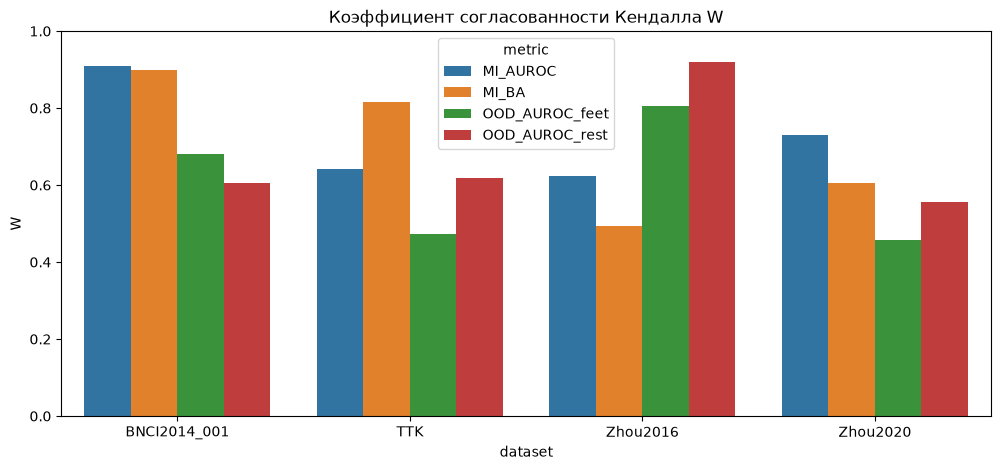

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))
sns.barplot(data=agreement, x="dataset", y="W", hue="metric", errorbar=None)
plt.title("Коэффициент согласованности Кендалла W")
plt.ylim(0, 1)
plt.show()

### По всем участникам

In [5]:
rows = []
for metric in [*MI_METRICS, *OOD_METRICS]:
    rows.append({"metric": metric, "n": len(wide), "W": pg.friedman(wide[metric].reset_index(drop=True).T)["W"].iloc[0]})

agreement_all = pd.DataFrame(rows).set_index("metric")
display(agreement_all.round(4))


,n,W
metric,,
MI_BA,39,0.8126
MI_AUROC,39,0.8398
OOD_AUROC_feet,39,0.6196
OOD_AUROC_rest,39,0.6599


## Согласованность методов OOD между feet и rest

Для каждого метода сопоставляем результаты feet и rest у одних и тех же участников внутри каждого датасета.

Проверяется корреляция Спирмена с перестановочным тестом (насколько одинаково детектор ранжирует участников в экспериментах с feet и rest). Используется парный критерий Уилкоксона для проверки систематических различие между значениями OOD AUROC.

Применяется поправка Холма, отдельно к p-value для проверки согласованности (p_rho_holm) и к p-value для проверки различий (p_wilcoxon_holm). 

In [6]:
rows = []
for dataset, x in [*wide.groupby(level="dataset"), ("ALL datasets", wide)]:
    for method in OOD_METHODS:
        pair = pd.DataFrame({"feet": x["OOD_AUROC_feet"][method], "rest": x["OOD_AUROC_rest"][method]}).dropna()
        diff = pair["feet"] - pair["rest"]

        if len(pair) >= 2 and pair["feet"].nunique() > 1 and pair["rest"].nunique() > 1:
            test = permutation_test((pair["feet"], pair["rest"]), lambda feet, rest: spearmanr(feet, rest).statistic, permutation_type="pairings", alternative="two-sided", n_resamples=9999, random_state=42)
            rho, p_rho = float(test.statistic), test.pvalue
        else:
            rho, p_rho = np.nan, np.nan

        if len(diff) >= 2 and np.any(diff != 0):
            test = wilcoxon(diff, alternative="two-sided")
            W, p_wilcoxon = float(test.statistic), float(test.pvalue)
        else:
            W, p_wilcoxon = np.nan, np.nan

        rows.append({"dataset": dataset, "method": method, "n": len(diff), "rho": rho, "p_rho": p_rho, "mean_diff": diff.mean(), "median_diff": diff.median(), "W": W, "p_wilcoxon": p_wilcoxon})

ood_comparison = pd.DataFrame(rows)
for p in ["p_rho", "p_wilcoxon"]:
    ood_comparison[f"{p}_holm"] = np.nan
    valid = ood_comparison[p].notna()
    ood_comparison.loc[valid, f"{p}_holm"] = pg.multicomp(ood_comparison.loc[valid, p], method="holm")[1]

display(ood_comparison.set_index(["dataset", "method"]).round(4))

n     rho   p_rho  mean_diff  \
dataset      method                                                     
BNCI2014_001 ACM+TS+OCSVM                9  0.8000  0.0128    -0.2484   
             FBCSP+IsolationForest       9  0.5000  0.1780    -0.1311   
             ShallowConvNet+kNN          9  0.4333  0.2368    -0.0597   
             EEGNet+TempDens             9  0.3933  0.2978    -0.1300   
             Log-bandpower+Mahalanobis   9  0.8333  0.0074    -0.1210   
             Microstates+LOF             9  0.4167  0.2740    -0.2199   
             VAR+Mahalanobis             9  0.4667  0.2210    -0.2647   
TTK          ACM+TS+OCSVM                6  0.1429  0.8040     0.0544   
             FBCSP+IsolationForest       6  0.2571  0.6422     0.0710   
             ShallowConvNet+kNN          6  0.3143  0.5512     0.0782   
             EEGNet+TempDens             6  0.6000  0.2394     0.1815   
             Log-bandpower+Mahalanobis   6  0.7714  0.0988     0.0064   
             Microstates+LOF             6  0.7143  0.1344     0.0780   
             VAR+Mahalanobis             6  0.3714  0.4998     0.0434   
Zhou2016     ACM+TS+OCSVM                4  1.0000  0.0833    -0.0250   
             FBCSP+IsolationForest       4  0.6000  0.4167     0.0787   
             ShallowConvNet+kNN          4  0.2000  0.9167     0.0194   
             EEGNet+TempDens             4  0.6000  0.4167     0.0734   
             Log-bandpower+Mahalanobis   4  0.8000  0.3333     0.0192   
             Microstates+LOF             4  0.8000  0.3333     0.1007   
             VAR+Mahalanobis             4  0.8000  0.3333     0.0028   
Zhou2020     ACM+TS+OCSVM               20  0.0962  0.6810    -0.0439   
             FBCSP+IsolationForest      20  0.7805  0.0004    -0.0248   
             ShallowConvNet+kNN         20  0.7865  0.0004     0.0136   
             EEGNet+TempDens            20  0.6511  0.0032    -0.0058   
             Log-bandpower+Mahalanobis  20  0.5835  0.0060    -0.0382   
             Microstates+LOF            20  0.5910  0.0076    -0.0171   
             VAR+Mahalanobis            20  0.6812  0.0024    -0.0338   
ALL datasets ACM+TS+OCSVM               39  0.3986  0.0096    -0.0740   
             FBCSP+IsolationForest      39  0.6368  0.0002    -0.0240   
             ShallowConvNet+kNN         39  0.6433  0.0002     0.0072   
             EEGNet+TempDens            39  0.5559  0.0004     0.0025   
             Log-bandpower+Mahalanobis  39  0.6595  0.0002    -0.0445   
             Microstates+LOF            39  0.4662  0.0032    -0.0372   
             VAR+Mahalanobis            39  0.4069  0.0104    -0.0714   

                                        median_diff      W  p_wilcoxon  \
dataset      method                                                      
BNCI2014_001 ACM+TS+OCSVM                   -0.2845    0.0      0.0039   
             FBCSP+IsolationForest          -0.1570    8.0      0.0977   
             ShallowConvNet+kNN             -0.0592   13.0      0.3008   
             EEGNet+TempDens                -0.1456    6.0      0.0547   
             Log-bandpower+Mahalanobis      -0.1788    9.0      0.1289   
             Microstates+LOF                -0.1911    1.0      0.0078   
             VAR+Mahalanobis                -0.2773    0.0      0.0039   
TTK          ACM+TS+OCSVM                    0.0164    7.0      0.5625   
             FBCSP+IsolationForest           0.0764    4.0      0.2188   
             ShallowConvNet+kNN              0.0644    5.0      0.3125   
             EEGNet+TempDens                 0.1803    1.0      0.0625   
             Log-bandpower+Mahalanobis       0.0187    9.0      0.8438   
             Microstates+LOF                 0.0926    2.0      0.0938   
             VAR+Mahalanobis                 0.0503    5.0      0.3125   
Zhou2016     ACM+TS+OCSVM                   -0.0333    1.0      0.2500   
             FBCSP+IsolationForest           0.0305    4.0      0.8750   
       

In [7]:
paired = pd.concat([
    pd.DataFrame({"feet": x["OOD_AUROC_feet"][method], "rest": x["OOD_AUROC_rest"][method]}).dropna().assign(dataset=dataset, method=method)
    for dataset, x in wide.groupby(level="dataset")
    for method in OOD_METHODS
], ignore_index=True)
paired["difference_feet_minus_rest"] = paired["feet"] - paired["rest"]

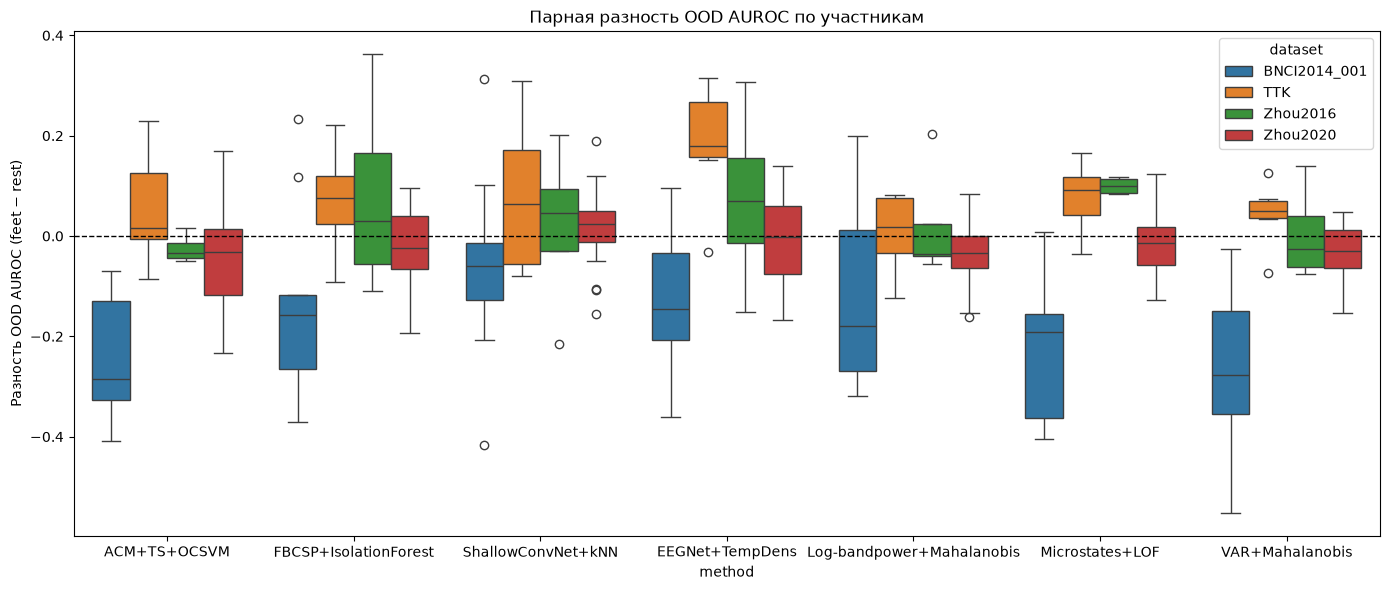

In [8]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=paired, x="method", y="difference_feet_minus_rest", hue="dataset")
plt.axhline(0, color="black", linewidth=1, linestyle="--")
plt.ylabel("Разность OOD AUROC (feet − rest)")
plt.title("Парная разность OOD AUROC по участникам")
plt.tight_layout()
plt.show()

## Связь MI BA, MI AUROC с OOD AUROC

Проверяем, связаны ли средние ранги MI и OOD среди участников этого датасета.

Считается корреляция Спирмена.

Для каждого участника считается и усредняется его ранг в каждом методе, затем проверяется связь этих показателей.

Rho > 0 -- участники с более высокими результатами классификации MI обычно имеют более высокие результаты детекции OOD.

Для определения значимости используется перестановочный тест, затем применяется поправка Холма.


In [9]:
rows = []
for dataset, x in [*wide.groupby(level="dataset"), ("ALL datasets", wide)]:
    profiles = rank_profiles(x)
    for ood_metric in OOD_METRICS:
        ood = profiles[ood_metric].to_numpy()
        for metric in MI_METRICS:
            mi = profiles[metric].to_numpy()
            test = permutation_test((ood,), lambda y: spearmanr(mi, y).statistic, permutation_type="pairings", alternative="two-sided", n_resamples=9999, random_state=42)
            rows.append({"dataset": dataset, "metric": f"{metric} ~ {ood_metric}", "n": len(x), "rho": test.statistic, "p_perm": test.pvalue})

association = pd.DataFrame(rows)
association["p_holm"] = pg.multicomp(association["p_perm"], method="holm")[1]
display(association.set_index(["metric", "dataset"]).round(4))


,,n,rho,p_perm,p_holm
metric,dataset,,,,
MI_BA ~ OOD_AUROC_feet,BNCI2014_001,9,0.3500,0.3588,1.0000
MI_AUROC ~ OOD_AUROC_feet,BNCI2014_001,9,0.4167,0.2726,1.0000
MI_BA ~ OOD_AUROC_rest,BNCI2014_001,9,0.3096,0.4046,1.0000
MI_AUROC ~ OOD_AUROC_rest,BNCI2014_001,9,0.3264,0.3756,1.0000
MI_BA ~ OOD_AUROC_feet,TTK,6,0.9276,0.0222,0.3111
MI_AUROC ~ OOD_AUROC_feet,TTK,6,0.7827,0.0778,0.8556
MI_BA ~ OOD_AUROC_rest,TTK,6,0.1429,0.8028,1.0000
MI_AUROC ~ OOD_AUROC_rest,TTK,6,0.0286,1.0000,1.0000
MI_BA ~ OOD_AUROC_feet,Zhou2016,4,-0.8944,0.3333,1.0000


### Корреляция Спирмена с учетом принадлежности к датасету

Неопределеность оценки при повторном выборе участников внутри каждого датасета (95% bootstrap интервалы)

In [10]:
adjusted_parts = []

for ood_metric in OOD_METRICS:
    ci = bootstrap_ci(wide, ood_metric=ood_metric)
    part = pd.DataFrame({"ood_metric": ood_metric, "n": len(wide), "rho": adjusted_rho(wide, ood_metric=ood_metric), "CI_low": ci.low, "CI_high": ci.high, "p_perm": permutation_p(wide, ood_metric=ood_metric)}, index=pd.Index(MI_METRICS, name="metric"))
    adjusted_parts.append(part.reset_index())

adjusted = pd.concat(adjusted_parts, ignore_index=True).set_index(["ood_metric", "metric"])
display(adjusted.round(4))


n     rho  CI_low  CI_high  p_perm
ood_metric     metric                                       
OOD_AUROC_feet MI_BA     39  0.5014  0.1939   0.6911  0.0021
               MI_AUROC  39  0.5336  0.2467   0.7178  0.0011
OOD_AUROC_rest MI_BA     39  0.3699  0.0089   0.6460  0.0275
               MI_AUROC  39  0.3936  0.0582   0.6657  0.0164

Средняя корреляция MI–OOD, рассчитанная отдельно в каждом датасете, с весами по числу участников

In [11]:
weighted_parts = []
for ood_metric in OOD_METRICS:
    part = pd.DataFrame({
        "ood_metric": ood_metric,
        "rho": weighted_rho(wide, ood_metric=ood_metric), 
        "p_perm": permutation_p(wide, statistic=weighted_rho, ood_metric=ood_metric) }, 
        index=pd.Index(MI_METRICS, name="metric")).reset_index()
    weighted_parts.append(part)

weighted = pd.concat(weighted_parts, ignore_index=True).set_index(["ood_metric", "metric"])
weighted["p_holm"] = pg.multicomp(weighted["p_perm"], method="holm")[1]
display(weighted.round(4))

rho  p_perm  p_holm
ood_metric     metric                          
OOD_AUROC_feet MI_BA     0.4084  0.0164  0.0492
               MI_AUROC  0.4391  0.0097  0.0388
OOD_AUROC_rest MI_BA     0.2200  0.2021  0.4042
               MI_AUROC  0.2025  0.2417  0.4042

## Средние ранги по участникам

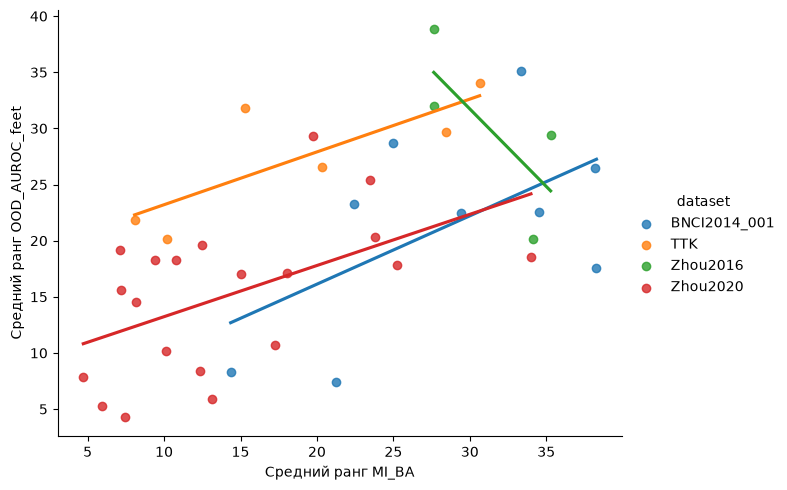

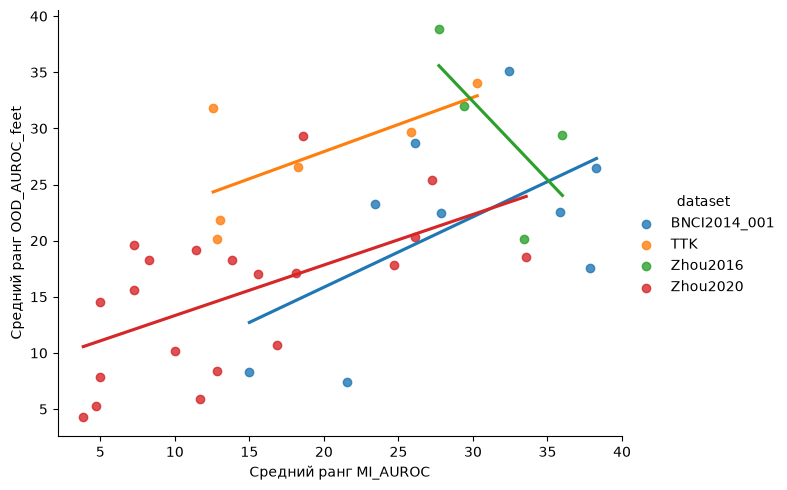

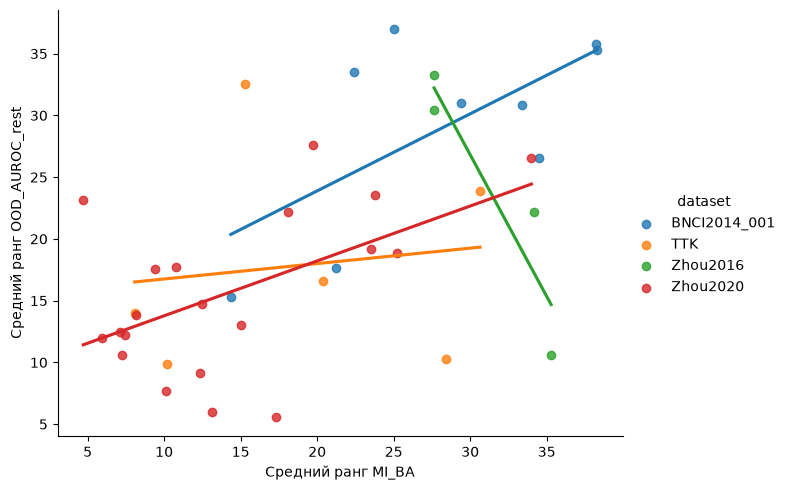

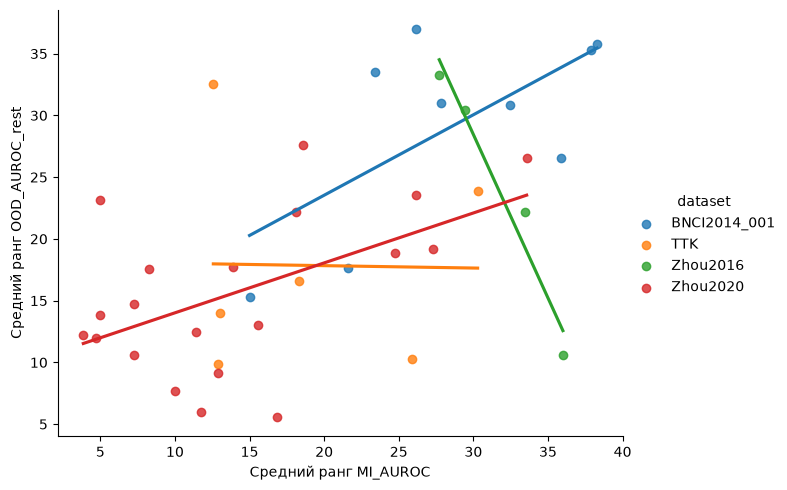

In [12]:
profiles = rank_profiles(wide).reset_index()
for ood_metric in OOD_METRICS:
    for metric in MI_METRICS:
        g = sns.lmplot(data=profiles, x=metric, y=ood_metric, hue="dataset", ci=None, truncate=True, height=5, aspect=1.3)
        g.set_axis_labels(f"Средний ранг {metric}", f"Средний ранг {ood_metric}")
        plt.show()

## Проверка устойчивости при исключении датасетов

In [13]:
rows = []
for kind, labels in [("dataset", wide.index.get_level_values("dataset").unique()), ("method", wide.columns.get_level_values("method").unique()), ("subject", wide.index)]:
    for label in labels:
        x = wide.drop(columns=label, level="method") if kind == "method" else wide.drop(index=label, level="dataset") if kind == "dataset" else wide.drop(index=[label])
        for ood_metric in OOD_METRICS:
            rows.append({"ood_metric": ood_metric, "removed": kind, "label": str(label), **dict(zip(MI_METRICS, adjusted_rho(x, ood_metric=ood_metric)))})

sensitivity = pd.DataFrame(rows)
display(sensitivity.melt(id_vars=["ood_metric", "removed", "label"], var_name="metric", value_name="rho").groupby(["ood_metric", "removed", "metric"])["rho"].agg(["min", "max"]).round(3))
display(sensitivity[sensitivity["removed"].eq("dataset")].round(3))


min    max
ood_metric     removed metric                
OOD_AUROC_feet dataset MI_AUROC  0.341  0.577
                       MI_BA     0.285  0.550
               method  MI_AUROC  0.454  0.599
                       MI_BA     0.440  0.574
               subject MI_AUROC  0.477  0.571
                       MI_BA     0.437  0.545
OOD_AUROC_rest dataset MI_AUROC  0.172  0.461
                       MI_BA     0.103  0.466
               method  MI_AUROC  0.331  0.425
                       MI_BA     0.332  0.398
               subject MI_AUROC  0.334  0.486
                       MI_BA     0.301  0.451

,ood_metric,removed,label,MI_BA,MI_AUROC
0,OOD_AUROC_feet,dataset,BNCI2014_001,0.503,0.577
1,OOD_AUROC_rest,dataset,BNCI2014_001,0.289,0.332
2,OOD_AUROC_feet,dataset,TTK,0.470,0.531
3,OOD_AUROC_rest,dataset,TTK,0.403,0.423
4,OOD_AUROC_feet,dataset,Zhou2016,0.550,0.576
5,OOD_AUROC_rest,dataset,Zhou2016,0.466,0.461
6,OOD_AUROC_feet,dataset,Zhou2020,0.285,0.341
7,OOD_AUROC_rest,dataset,Zhou2020,0.103,0.172


## Результат проверки гипотез

Сводка включает согласованность MI-классификаторов (H1), OOD-детекторов отдельно для каждой OOD-категории (H2) и связь MI–OOD отдельно в каждой страте (H3).


In [14]:
agreement_overall = pd.DataFrame([{"metric": metric, "dataset": "ALL weighted", **overall_agreement(wide[metric])} for metric in [*MI_METRICS, *OOD_METRICS]])
summary = pd.concat([agreement, agreement_overall], ignore_index=True).rename(columns={"W": "effect"}).assign(coefficient="W")
summary = pd.concat([summary, adjusted.reset_index().rename(columns={"rho": "effect"}).assign(dataset="ALL adjusted", coefficient="rho")], ignore_index=True)
summary["hypothesis"] = np.where(summary["coefficient"].eq("rho"), "H3: MI–OOD association", 
                        np.where(summary["metric"].isin(OOD_METRICS), "H2: OOD agreement", 
                        "H1: MI agreement"))
summary["ood_metric"] = summary["ood_metric"].fillna(summary["metric"].where(summary["metric"].isin(OOD_METRICS)))
mask = summary["dataset"].isin(["ALL weighted", "ALL adjusted"])
summary.loc[mask, "p_holm"] = pg.multicomp(summary.loc[mask, "p_perm"], method="holm")[1]
summary["significant"] = summary["p_holm"] < 0.05
display(summary.loc[mask, ["hypothesis", "ood_metric", "metric", "dataset", "n", "coefficient", "effect", "p_perm", "p_holm", "significant"]].round(4))

,hypothesis,ood_metric,metric,dataset,n,coefficient,effect,p_perm,p_holm,significant
16,H1: MI agreement,NaN,MI_BA,ALL weighted,39,W,0.6945,0.0001,0.0008,True
17,H1: MI agreement,NaN,MI_AUROC,ALL weighted,39,W,0.7466,0.0001,0.0008,True
18,H2: OOD agreement,OOD_AUROC_feet,OOD_AUROC_feet,ALL weighted,39,W,0.5466,0.0001,0.0008,True
19,H2: OOD agreement,OOD_AUROC_rest,OOD_AUROC_rest,ALL weighted,39,W,0.6138,0.0001,0.0008,True
20,H3: MI–OOD association,OOD_AUROC_feet,MI_BA,ALL adjusted,39,rho,0.5014,0.0021,0.0063,True
21,H3: MI–OOD association,OOD_AUROC_feet,MI_AUROC,ALL adjusted,39,rho,0.5336,0.0011,0.0044,True
22,H3: MI–OOD association,OOD_AUROC_rest,MI_BA,ALL adjusted,39,rho,0.3699,0.0275,0.0328,True
23,H3: MI–OOD association,OOD_AUROC_rest,MI_AUROC,ALL adjusted,39,rho,0.3936,0.0164,0.0328,True


## Корреляции отдельных методов по участникам

Корреляции Спирмена. 

Столбцы и строки отсортированы по BA/AUROC методов.

### По всем участникам

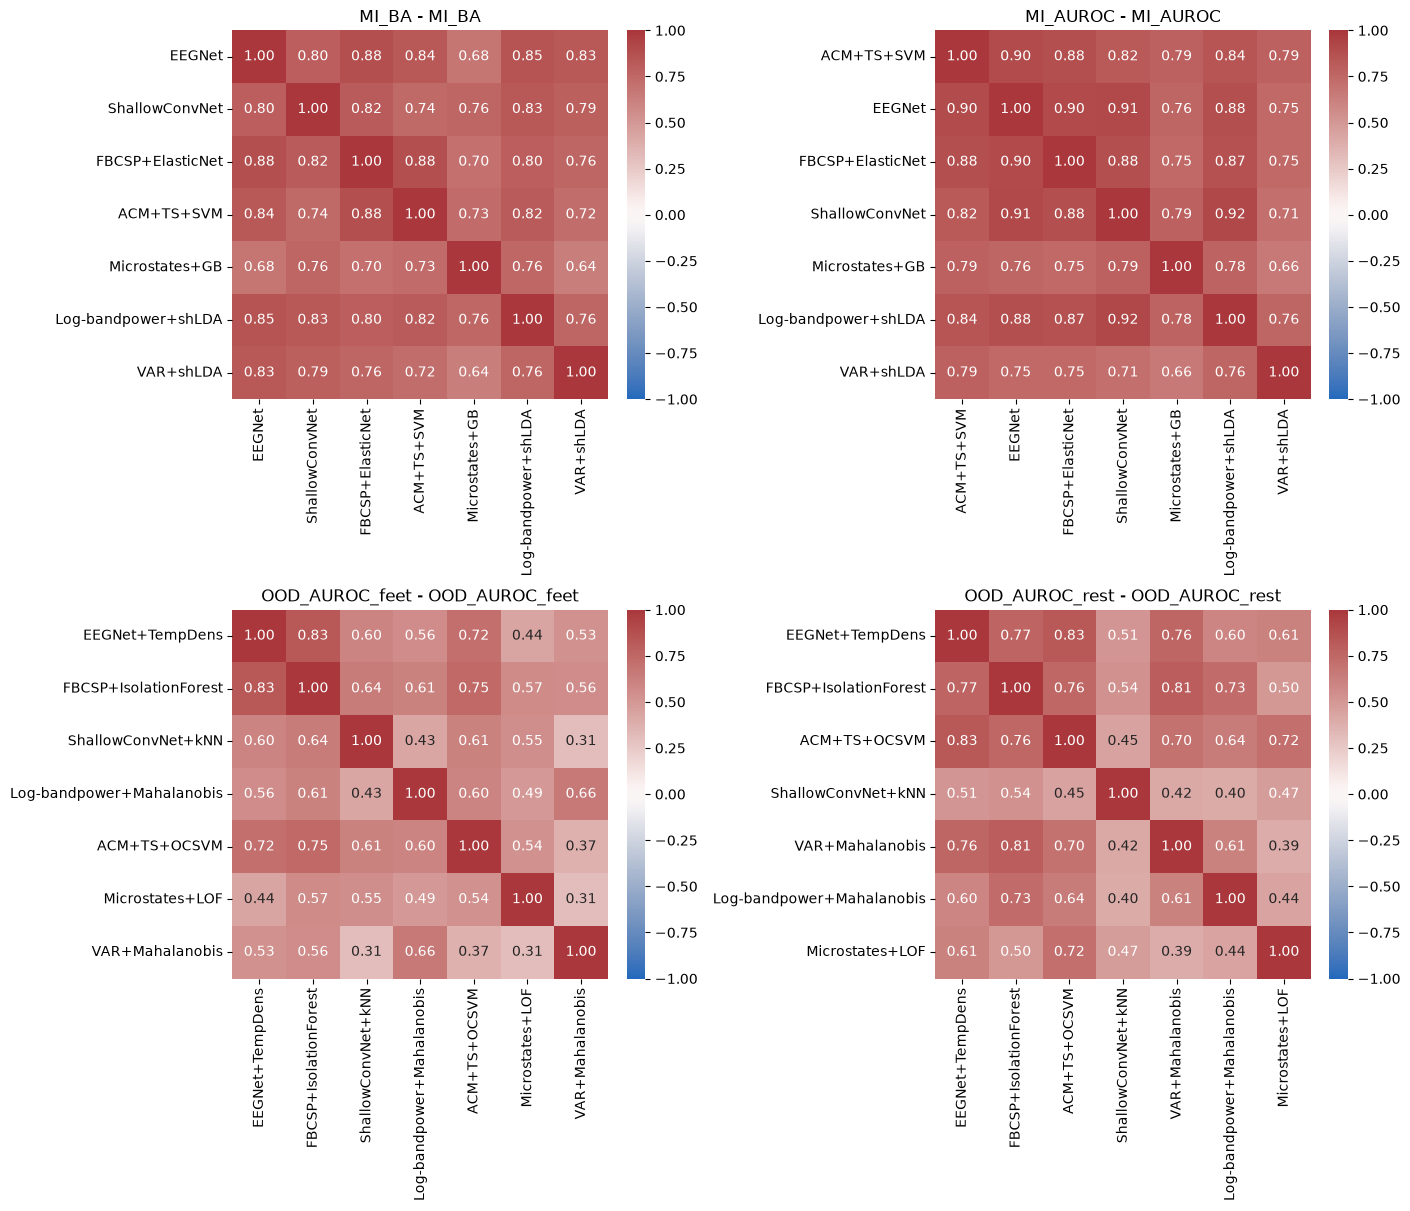

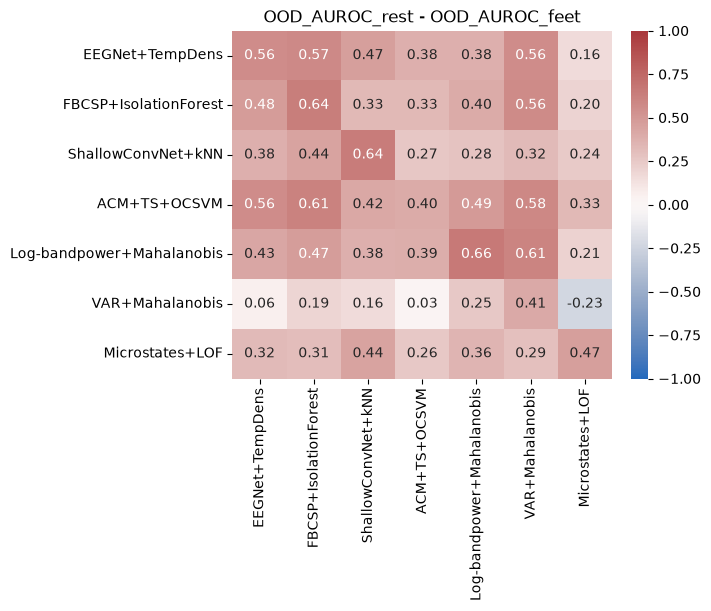

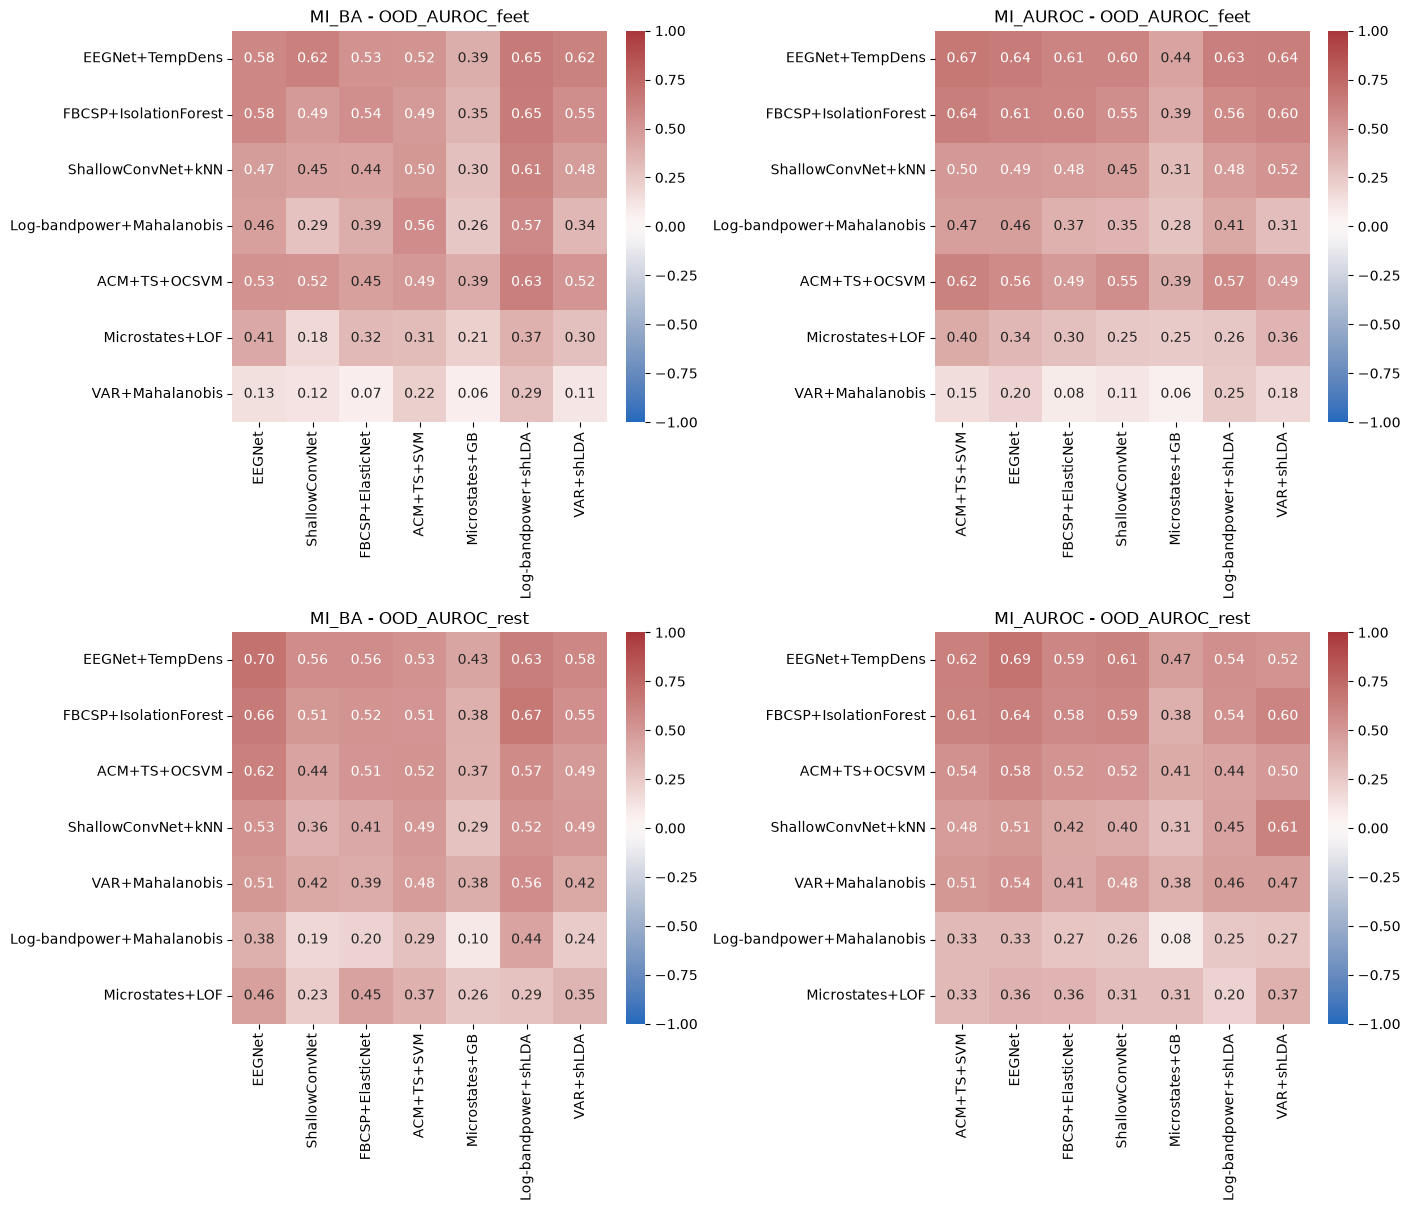

In [15]:
corr = wide.corr(method="spearman")

within = [(m, m) for m in [*MI_METRICS, *OOD_METRICS]]
between = [(ood_metric, m) for ood_metric in OOD_METRICS for m in MI_METRICS]
between_ood = [("OOD_AUROC_feet", "OOD_AUROC_rest")]
ood_order = pd.concat([wide[m].mean().rename(m) for m in OOD_METRICS], axis=1).mean(axis=1).sort_values(ascending=False).index

for panels in [within, between_ood, between]:
    ncols = 1 if len(panels) == 1 else 2
    nrows = (len(panels) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 6 * nrows), layout="constrained")
    axes = np.atleast_1d(axes).ravel()
    for ax, (a, b) in zip(axes, panels):
        matrix = corr.xs(a).xs(b, axis=1)
        #matrix = matrix.reindex(index=wide[a].mean().sort_values(ascending=False).index, columns=wide[b].mean().sort_values(ascending=False).index)
        if {a, b} == set(OOD_METRICS):
            matrix = matrix.reindex(index=ood_order, columns=ood_order)
        else:
            matrix = matrix.reindex(index=wide[a].mean().sort_values(ascending=False).index, columns=wide[b].mean().sort_values(ascending=False).index)
        sns.heatmap(matrix, ax=ax, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0)
        ax.set(title=f"{b} - {a}", xlabel="", ylabel="")
    plt.show()

### Взвешенное среднее по датасетам

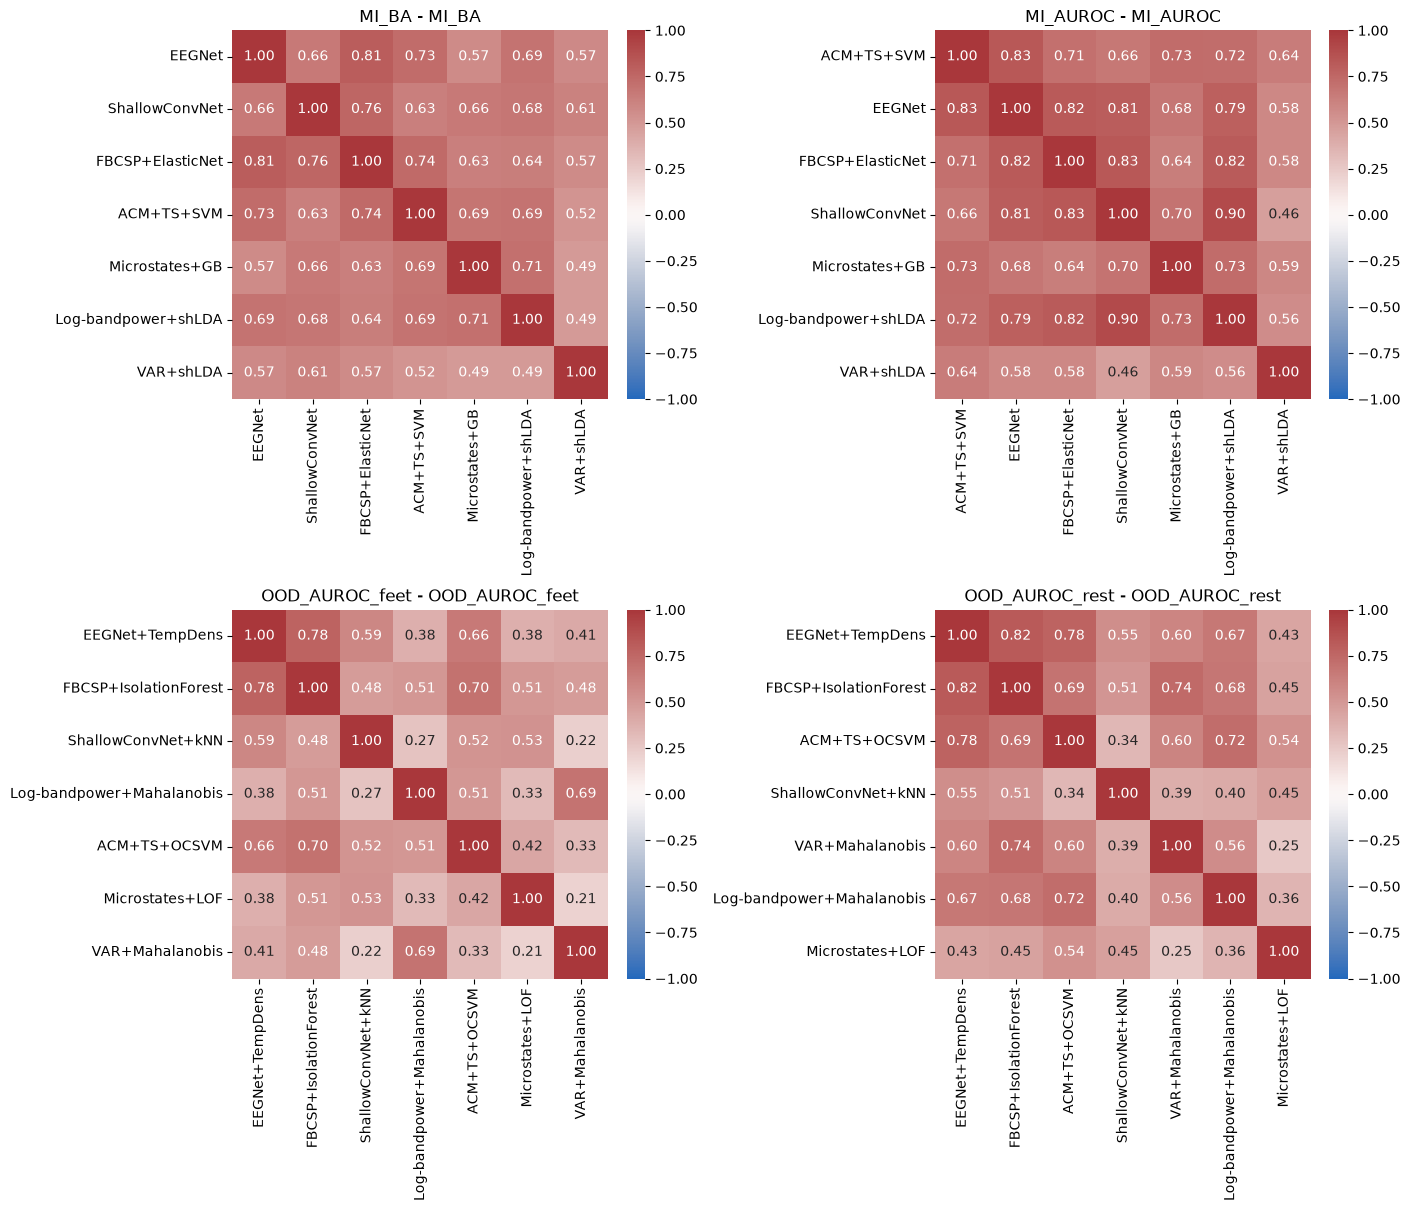

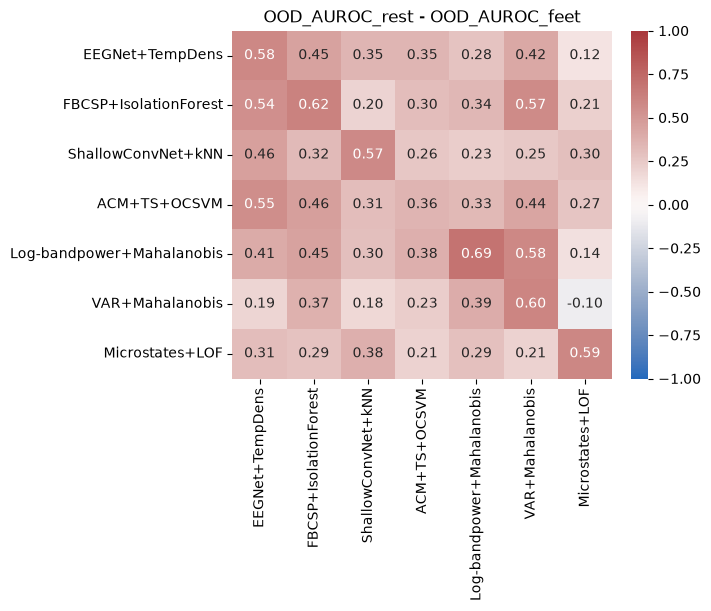

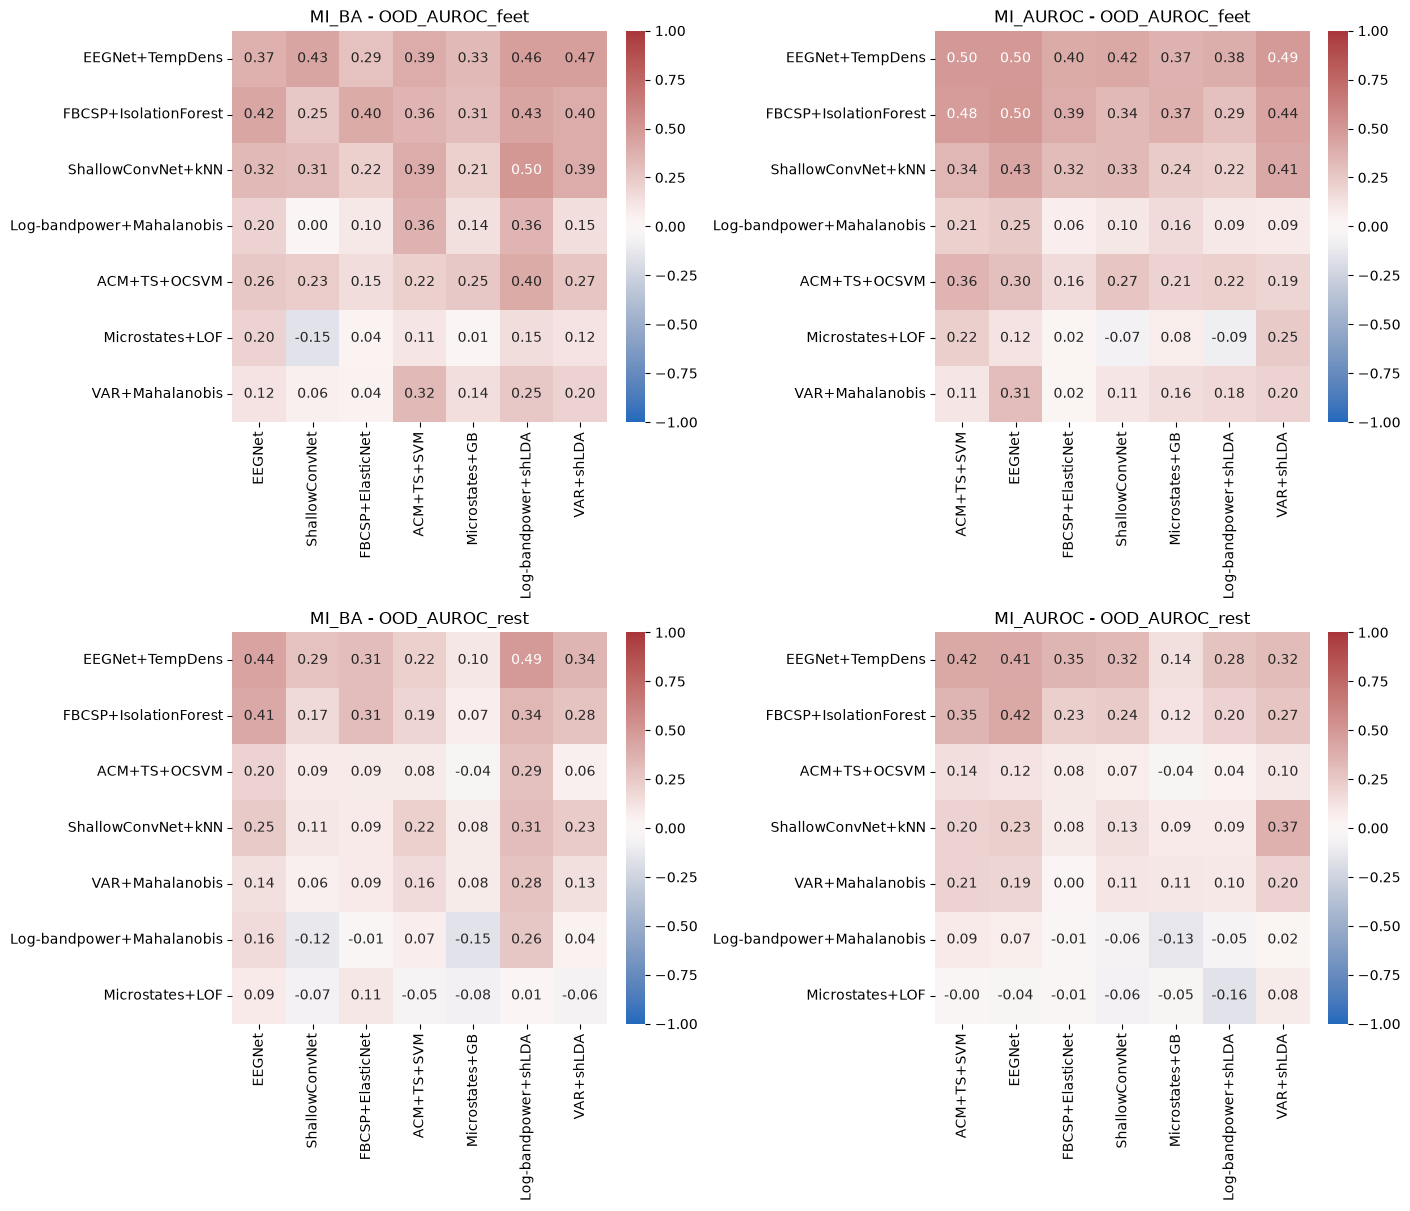

In [16]:
parts = [x for _, x in wide.groupby(level="dataset") if len(x) >= 3]
corr_within = pd.DataFrame(np.average([x.corr(method="spearman").to_numpy() for x in parts], axis=0, weights=[len(x) for x in parts]), index=wide.columns, columns=wide.columns)

within = [(m, m) for m in [*MI_METRICS, *OOD_METRICS]]
between = [(ood_metric, m) for ood_metric in OOD_METRICS for m in MI_METRICS]
between_ood = [("OOD_AUROC_feet", "OOD_AUROC_rest")]
ood_order = pd.concat([wide[m].mean().rename(m) for m in OOD_METRICS], axis=1).mean(axis=1).sort_values(ascending=False).index

for panels in [within, between_ood, between]:
    ncols = 1 if len(panels) == 1 else 2
    nrows = (len(panels) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 6 * nrows), layout="constrained")
    axes = np.atleast_1d(axes).ravel()
    for ax, (a, b) in zip(axes, panels):
        matrix = corr_within.xs(a).xs(b, axis=1)
        #matrix = matrix.reindex(index=wide[a].mean().sort_values(ascending=False).index, columns=wide[b].mean().sort_values(ascending=False).index)
        if {a, b} == set(OOD_METRICS):
            matrix = matrix.reindex(index=ood_order, columns=ood_order)
        else:
            matrix = matrix.reindex(index=wide[a].mean().sort_values(ascending=False).index, columns=wide[b].mean().sort_values(ascending=False).index)
        sns.heatmap(matrix, ax=ax, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0)
        ax.set(title=f"{b} - {a}", xlabel="", ylabel="")
    plt.show()

Корреляции между методами

In [17]:
rows = []
for metric in MI_METRICS:
    for ood_metric in OOD_METRICS:
        r = corr_within.xs(ood_metric).xs(metric, axis=1).to_numpy().ravel()
        rows.append({"metric": metric, "ood_metric": ood_metric, "median_rho": np.median(r), "min_rho": r.min(), "max_rho": r.max(), "positive_pairs": int((r > 0).sum()), "pairs": r.size})
display(pd.DataFrame(rows).set_index(["ood_metric", "metric"]).round(3))

,,median_rho,min_rho,max_rho,positive_pairs,pairs
ood_metric,metric,,,,,
OOD_AUROC_feet,MI_BA,0.255,-0.153,0.503,48,49
OOD_AUROC_rest,MI_BA,0.107,-0.150,0.488,41,49
OOD_AUROC_feet,MI_AUROC,0.245,-0.089,0.504,47,49
OOD_AUROC_rest,MI_AUROC,0.107,-0.156,0.421,38,49


## Результаты по участникам

Строки упорядочены по медиане MI BA, столбцы упорядочены по BA/AUROC.

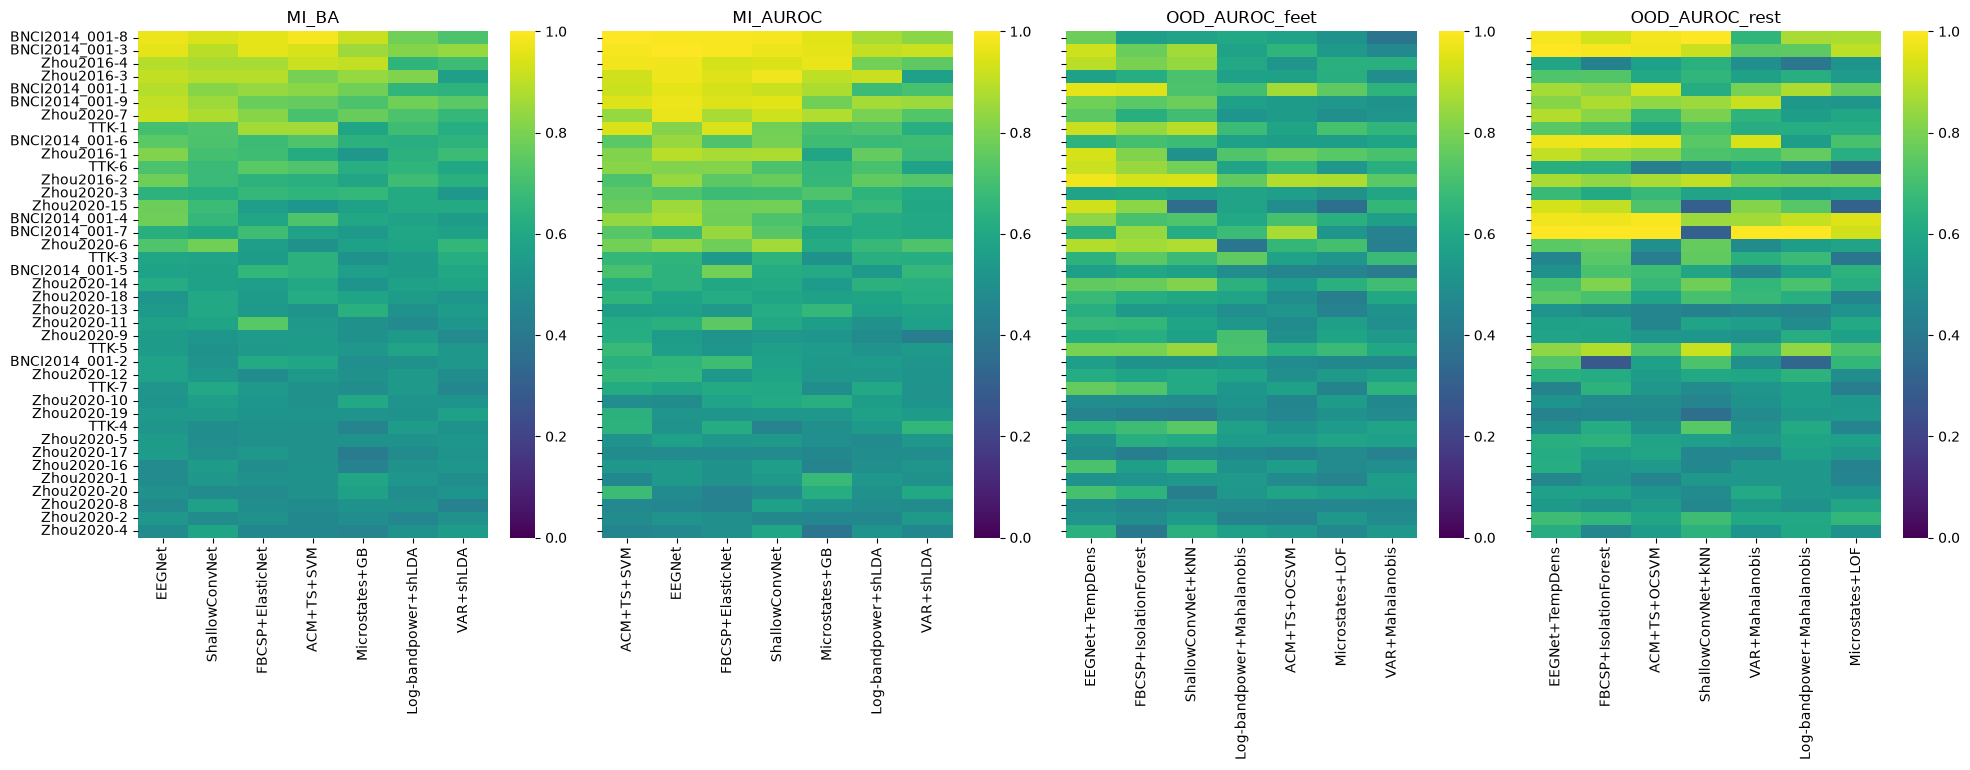

In [18]:
ordered = wide.loc[wide["MI_BA"].median(axis=1).sort_values(ascending=False).index]
fig, axes = plt.subplots(1, 4, figsize=(20, max(6, len(wide) * .2)), sharey=True)
for ax, metric in zip(axes, ["MI_BA", "MI_AUROC", "OOD_AUROC_feet", "OOD_AUROC_rest"]):
    t = ordered[metric]
    t = t.loc[:, t.mean().sort_values(ascending=False).index]
    sns.heatmap(t, ax=ax, cmap="viridis", vmin=0, vmax=1, yticklabels=True)
    ax.set(title=metric, xlabel="", ylabel="")
    ax.tick_params(axis="y", labelleft=ax is axes[0])
plt.tight_layout()
plt.show()

## Распределения всех сочетаний методов внутри участников

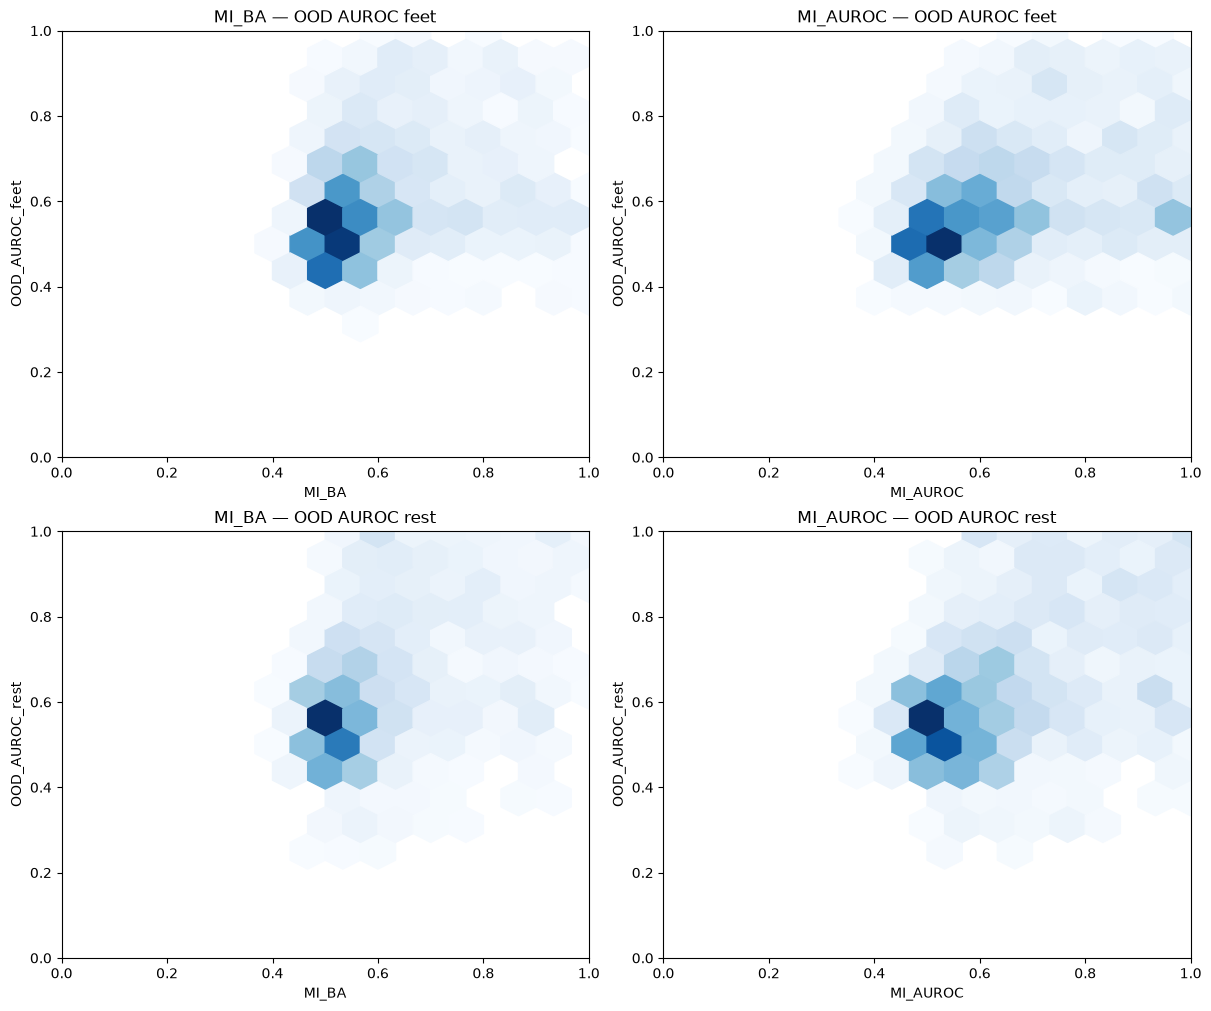

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10), layout="constrained")
panel = 0

for ood_metric in OOD_METRICS:
    ood_long = wide[ood_metric].stack().rename("OOD").reset_index()
    for metric in MI_METRICS:
        pairs = wide[metric].stack().rename("MI").reset_index().merge(
            ood_long, on=["dataset", "subject"])
        #g = sns.jointplot(data=pairs, x="MI", y="OOD", kind="hex", height=6,
        #                xlim=(0, 1), ylim=(0, 1), gridsize=15,
        #                extent=(0, 1, 0, 1), mincnt=1, color="steelblue")
        #g.set_axis_labels(metric, "OOD AUROC")
        ax = axes.flat[panel]
        ax.hexbin(pairs["MI"], pairs["OOD"], gridsize=15, extent=(0, 1, 0, 1), mincnt=1, cmap="Blues")
        category = ood_metric.rsplit("_", 1)[-1]
        ax.set(xlim=(0, 1), ylim=(0, 1), xlabel=metric, ylabel=ood_metric, title=f"{metric} — OOD AUROC {category}")
        panel += 1
plt.show()